# Statistical Analysis of HR Employee Attrition

## Objective

The objective of this notebook is to statistically investigate the relationships between employee characteristics and attrition.

The analysis will use statistical techniques to evaluate patterns identified during exploratory data analysis.

## Statistical Methods

1. Correlation analysis
2. Chi-square test of independence
3. Independent samples hypothesis testing
4. Confidence intervals
5. Effect size analysis

## Dataset

The analysis uses the cleaned IBM HR Analytics Employee Attrition dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

df = pd.read_csv("../data/processed/cleaned_hr_data.csv")

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeNumber,EnvironmentSatisfaction,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,2,...,3,1,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,2,3,...,4,4,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,4,...,3,2,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,5,4,...,3,3,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,7,1,...,3,4,1,6,3,3,2,2,2,2


In [2]:
df.shape

(1470, 32)

In [3]:
df["Attrition_Flag"] = df["Attrition"].map({"Yes": 1, "No": 0})

df[["Attrition", "Attrition_Flag"]].head()

,Attrition,Attrition_Flag
0,Yes,1
1,No,0
2,Yes,1
3,No,0
4,No,0


In [4]:
df["Attrition_Flag"].value_counts()

Attrition_Flag
0    1233
1     237
Name: count, dtype: int64

In [5]:
numerical_columns = [
    "Age",
    "DailyRate",
    "DistanceFromHome",
    "HourlyRate",
    "MonthlyIncome",
    "MonthlyRate",
    "NumCompaniesWorked",
    "PercentSalaryHike",
    "TotalWorkingYears",
    "TrainingTimesLastYear",
    "YearsAtCompany",
    "YearsInCurrentRole",
    "YearsSinceLastPromotion",
    "YearsWithCurrManager",
]

correlation_with_attrition = (
    df[numerical_columns + ["Attrition_Flag"]]
    .corr()["Attrition_Flag"]
    .drop("Attrition_Flag")
    .sort_values()
)

display(correlation_with_attrition)

TotalWorkingYears         -0.171063
YearsInCurrentRole        -0.160545
MonthlyIncome             -0.159840
Age                       -0.159205
YearsWithCurrManager      -0.156199
YearsAtCompany            -0.134392
TrainingTimesLastYear     -0.059478
DailyRate                 -0.056652
YearsSinceLastPromotion   -0.033019
PercentSalaryHike         -0.013478
HourlyRate                -0.006846
MonthlyRate                0.015170
NumCompaniesWorked         0.043494
DistanceFromHome           0.077924
Name: Attrition_Flag, dtype: float64

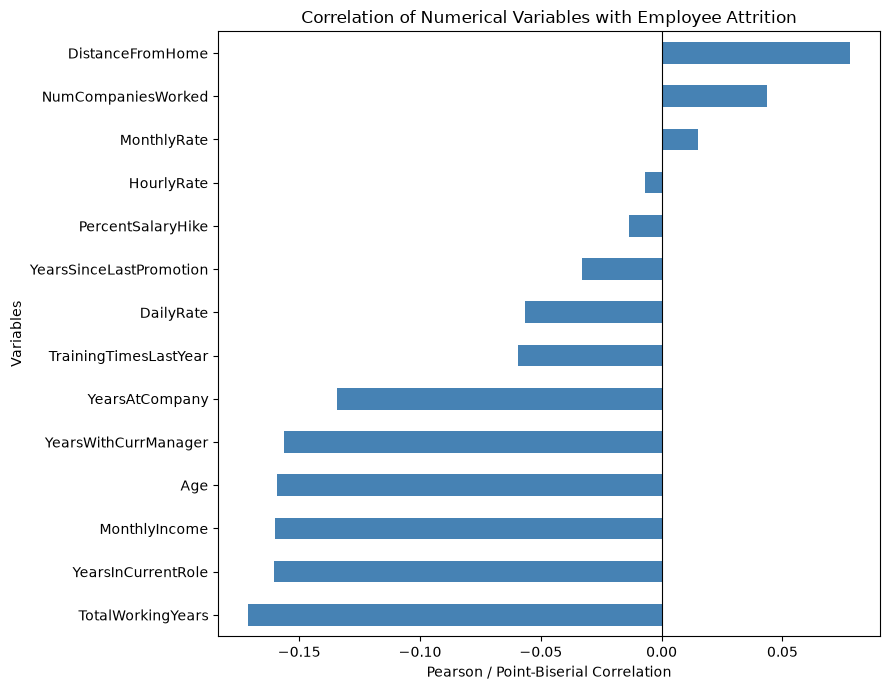

In [6]:
plt.figure(figsize=(9, 7))

correlation_with_attrition.sort_values().plot(kind="barh", color="steelblue")

plt.title("Correlation of Numerical Variables with Employee Attrition")
plt.xlabel("Pearson / Point-Biserial Correlation")
plt.ylabel("Variables")
plt.axvline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()

## Correlation Analysis: Key Findings

1. TotalWorkingYears has the strongest negative correlation with attrition (-0.1711).
2. YearsInCurrentRole (-0.1605), MonthlyIncome (-0.1598), and Age (-0.1592) also show weak negative correlations with attrition.
3. DistanceFromHome has the strongest positive correlation (0.0779), although the relationship is very weak.
4. NumCompaniesWorked shows a weak positive correlation (0.0435).
5. Most numerical variables have correlation coefficients close to zero, indicating weak linear associations with attrition.

### Interpretation

The results suggest that employees with greater work experience, higher income, and longer tenure tend to have slightly lower attrition in this dataset.

However, the observed correlations are weak, indicating that no single numerical variable provides a strong linear explanation of employee attrition.

### Limitations

- Correlation does not establish causation.
- Pearson correlation measures linear relationships and may not capture nonlinear patterns.
- Correlations between individual variables do not account for interactions or confounding factors.
- Statistical significance and practical importance must be investigated separately.

### Conclusion

Correlation analysis provides an initial understanding of relationships between numerical employee characteristics and attrition. Further statistical testing is required to investigate whether the observed associations are statistically significant.

In [7]:
overtime_table = pd.crosstab(df["OverTime"], df["Attrition"])

display(overtime_table)

Attrition,No,Yes
OverTime,,
No,944,110
Yes,289,127


In [8]:
chi2, p_value, dof, expected = stats.chi2_contingency(overtime_table)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

Chi-square statistic: 87.56429365828768
P-value: 8.15842372153832e-21
Degrees of freedom: 1


In [9]:
expected_table = pd.DataFrame(
    expected, index=overtime_table.index, columns=overtime_table.columns
)

display(expected_table)

Attrition,No,Yes
OverTime,,
No,884.069388,169.930612
Yes,348.930612,67.069388


## Chi-Square Test: Overtime vs Employee Attrition

### Hypotheses

- **Null Hypothesis (H₀):** Overtime status and employee attrition are independent.
- **Alternative Hypothesis (H₁):** Overtime status and employee attrition are associated.

### Test Results

- Chi-square statistic: 87.5643
- Degrees of freedom: 1
- P-value: 8.1584 × 10⁻²¹
- Significance level: 0.05

### Decision

Since the p-value is significantly lower than 0.05, we reject the null hypothesis.

### Interpretation

There is statistically significant evidence of an association between overtime status and employee attrition.

The observed contingency table shows that employees working overtime have a substantially higher proportion of departures than employees not working overtime.

### Assumption Check

All expected cell frequencies are greater than 5, satisfying the commonly used expected-frequency guideline for the chi-square approximation.

### Conclusion

Overtime status is statistically associated with employee attrition in this dataset. However, this test does not establish that overtime causes employees to leave.

In [10]:
n = overtime_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (n * min(overtime_table.shape[0] - 1, overtime_table.shape[1] - 1))
)

print("Cramér's V:", cramers_v)

Cramér's V: 0.24406463632881792


### Effect Size Analysis: Cramér's V

**Result:**

Cramér's V = 0.2441

**Interpretation:**

The calculated Cramér's V indicates a small-to-moderate association between overtime status and employee attrition.

Combined with the statistically significant chi-square test result, this suggests that overtime status is meaningfully associated with employee attrition in the dataset.

**Conclusion:**

Overtime status is statistically associated with attrition, with a small-to-moderate association strength. However, this result does not establish a causal relationship between overtime and employee turnover.

In [11]:
jobrole_table = pd.crosstab(df["JobRole"], df["Attrition"])

display(jobrole_table)

Attrition,No,Yes
JobRole,,
Healthcare Representative,122,9
Human Resources,40,12
Laboratory Technician,197,62
Manager,97,5
Manufacturing Director,135,10
Research Director,78,2
Research Scientist,245,47
Sales Executive,269,57
Sales Representative,50,33


In [12]:
chi2_job, p_job, dof_job, expected_job = stats.chi2_contingency(jobrole_table)

print("Chi-square statistic:", chi2_job)
print("P-value:", p_job)
print("Degrees of freedom:", dof_job)

Chi-square statistic: 86.19025367670434
P-value: 2.752481638050657e-15
Degrees of freedom: 8


In [13]:
expected_job_table = pd.DataFrame(
    expected_job, index=jobrole_table.index, columns=jobrole_table.columns
)

display(expected_job_table)

Attrition,No,Yes
JobRole,,
Healthcare Representative,109.879592,21.120408
Human Resources,43.616327,8.383673
Laboratory Technician,217.242857,41.757143
Manager,85.555102,16.444898
Manufacturing Director,121.622449,23.377551
Research Director,67.102041,12.897959
Research Scientist,244.922449,47.077551
Sales Executive,273.440816,52.559184
Sales Representative,69.618367,13.381633


In [14]:
n_job = jobrole_table.to_numpy().sum()

cramers_v_job = np.sqrt(
    chi2_job / (n_job * min(jobrole_table.shape[0] - 1, jobrole_table.shape[1] - 1))
)

print("Cramér's V:", cramers_v_job)

Cramér's V: 0.24214215996065436


## Chi-Square Test: Job Role vs Employee Attrition

### Hypotheses

- **Null Hypothesis (H₀):** Job role and employee attrition are independent.
- **Alternative Hypothesis (H₁):** Job role and employee attrition are associated.

### Test Results

- Chi-square statistic: 86.1903
- Degrees of freedom: 8
- P-value: 2.7525 × 10⁻¹⁵
- Cramér's V: 0.2421
- Significance level: 0.05

### Assumption Check

All expected cell frequencies are greater than 5, satisfying the commonly used expected-frequency guideline for the chi-square approximation.

### Decision

Since the p-value is significantly lower than 0.05, we reject the null hypothesis.

### Interpretation

There is statistically significant evidence of an association between job role and employee attrition.

Cramér's V of 0.2421 indicates a small-to-moderate association between these variables.

### Conclusion

Job role is statistically associated with employee attrition in this dataset. However, the test does not establish that job role causes employees to leave.

In [15]:
travel_table = pd.crosstab(df["BusinessTravel"], df["Attrition"])

display(travel_table)

Attrition,No,Yes
BusinessTravel,,
Non-Travel,138,12
Travel_Frequently,208,69
Travel_Rarely,887,156


In [17]:
chi2_travel, p_travel, dof_travel, expected_travel = stats.chi2_contingency(
    travel_table
)

print("Chi-square statistic:", chi2_travel)
print("P-value:", p_travel)
print("Degrees of freedom:", dof_travel)

Chi-square statistic: 24.182413685655174
P-value: 5.608614476449931e-06
Degrees of freedom: 2


In [18]:
expected_travel_table = pd.DataFrame(
    expected_travel, index=travel_table.index, columns=travel_table.columns
)

display(expected_travel_table)

Attrition,No,Yes
BusinessTravel,,
Non-Travel,125.816327,24.183673
Travel_Frequently,232.340816,44.659184
Travel_Rarely,874.842857,168.157143


In [19]:
n_travel = travel_table.to_numpy().sum()

cramers_v_travel = np.sqrt(
    chi2_travel / (n_travel * min(travel_table.shape[0] - 1, travel_table.shape[1] - 1))
)

print("Cramér's V:", cramers_v_travel)

Cramér's V: 0.12825997643406717


## Chi-Square Test: Business Travel vs Employee Attrition

### Hypotheses

- **Null Hypothesis (H₀):** Business travel frequency and employee attrition are independent.
- **Alternative Hypothesis (H₁):** Business travel frequency and employee attrition are associated.

### Test Results

- Chi-square statistic: 24.1824
- Degrees of freedom: 2
- P-value: 5.6086 × 10⁻⁶
- Cramér's V: 0.1283
- Significance level: 0.05

### Assumption Check

All expected cell frequencies are greater than 5, satisfying the commonly used expected-frequency guideline for the chi-square approximation.

### Decision

Since the p-value is lower than 0.05, we reject the null hypothesis.

### Interpretation

There is statistically significant evidence of an association between business travel frequency and employee attrition.

Cramér's V of 0.1283 indicates a small association between the two variables.

### Conclusion

Business travel frequency is statistically associated with employee attrition in this dataset. However, the association is relatively weak, and the test does not establish that frequent business travel causes employees to leave.m

### Chi-Square Test: Job Satisfaction vs Attrition

In [23]:
job_sat_table = pd.crosstab(df["JobSatisfaction"], df["Attrition"])

display(job_sat_table)

Attrition,No,Yes
JobSatisfaction,,
1,223,66
2,234,46
3,369,73
4,407,52


In [24]:
chi2_job, p_job, dof_job, expected_job = stats.chi2_contingency(job_sat_table)

print("Chi-square statistic:", chi2_job)
print("P-value:", p_job)
print("Degrees of freedom:", dof_job)

Chi-square statistic: 17.505077010348
P-value: 0.0005563004510387556
Degrees of freedom: 3


In [25]:
expected_job_table = pd.DataFrame(
    expected_job, index=job_sat_table.index, columns=job_sat_table.columns
)

display(expected_job_table)

print("Minimum expected frequency:", expected_job.min())

Attrition,No,Yes
JobSatisfaction,,
1,242.406122,46.593878
2,234.857143,45.142857
3,370.738776,71.261224
4,384.997959,74.002041


Minimum expected frequency: 45.142857142857146


In [26]:
n_job = job_sat_table.to_numpy().sum()

cramers_v_job = np.sqrt(
    chi2_job / (n_job * min(job_sat_table.shape[0] - 1, job_sat_table.shape[1] - 1))
)

print("Cramér's V:", cramers_v_job)

Cramér's V: 0.1091247710343438


In [27]:
job_sat_analysis = job_sat_table.copy()

job_sat_analysis["Total_Employees"] = job_sat_analysis["No"] + job_sat_analysis["Yes"]

job_sat_analysis["Attrition_Rate"] = (
    job_sat_analysis["Yes"] / job_sat_analysis["Total_Employees"]
) * 100

display(job_sat_analysis)

Attrition,No,Yes,Total_Employees,Attrition_Rate
JobSatisfaction,,,,
1,223,66,289,22.837370
2,234,46,280,16.428571
3,369,73,442,16.515837
4,407,52,459,11.328976


## Chi-Square Test: Job Satisfaction vs Employee Attrition

### Hypotheses

- **Null Hypothesis (H₀):** Job satisfaction and employee attrition are independent.
- **Alternative Hypothesis (H₁):** Job satisfaction and employee attrition are associated.

### Test Results

- Chi-square statistic: 17.5051
- Degrees of freedom: 3
- P-value: 0.0005563
- Cramér's V: 0.1091
- Significance level: 0.05

### Assumption Check

All expected cell frequencies are greater than 5. The minimum expected frequency is 45.1429, satisfying the commonly used expected-frequency guideline for the Chi-square test.

### Decision

Since the p-value (0.0005563) is less than the significance level (0.05), we reject the null hypothesis.

### Interpretation

There is statistically significant evidence of an association between job satisfaction and employee attrition.

Employees with low job satisfaction have the highest attrition rate of 22.84%, while employees with very high job satisfaction have the lowest attrition rate of 11.33%.

Cramér's V of 0.1091 indicates a weak association between these variables.

### Conclusion

Job satisfaction is statistically associated with employee attrition in this dataset. Employees reporting lower job satisfaction show higher observed attrition rates. However, the association is relatively weak, and this analysis does not establish a causal relationship.

In [28]:
wlb_table = pd.crosstab(df["WorkLifeBalance"], df["Attrition"])

display(wlb_table)

Attrition,No,Yes
WorkLifeBalance,,
1,55,25
2,286,58
3,766,127
4,126,27


In [29]:
chi2_wlb, p_wlb, dof_wlb, expected_wlb = stats.chi2_contingency(wlb_table)

print("Chi-square statistic:", chi2_wlb)
print("P-value:", p_wlb)
print("Degrees of freedom:", dof_wlb)

Chi-square statistic: 16.3250970916474
P-value: 0.0009725698845348824
Degrees of freedom: 3


In [30]:
expected_wlb_table = pd.DataFrame(
    expected_wlb, index=wlb_table.index, columns=wlb_table.columns
)

display(expected_wlb_table)

print("Minimum expected frequency:", expected_wlb.min())

Attrition,No,Yes
WorkLifeBalance,,
1,67.102041,12.897959
2,288.538776,55.461224
3,749.026531,143.973469
4,128.332653,24.667347


Minimum expected frequency: 12.89795918367347


In [31]:
n_wlb = wlb_table.to_numpy().sum()

cramers_v_wlb = np.sqrt(
    chi2_wlb / (n_wlb * min(wlb_table.shape[0] - 1, wlb_table.shape[1] - 1))
)

print("Cramér's V:", cramers_v_wlb)

Cramér's V: 0.10538267516821954


In [32]:
wlb_analysis = wlb_table.copy()

wlb_analysis["Total_Employees"] = wlb_analysis["No"] + wlb_analysis["Yes"]

wlb_analysis["Attrition_Rate"] = (
    wlb_analysis["Yes"] / wlb_analysis["Total_Employees"]
) * 100

display(wlb_analysis)

Attrition,No,Yes,Total_Employees,Attrition_Rate
WorkLifeBalance,,,,
1,55,25,80,31.250000
2,286,58,344,16.860465
3,766,127,893,14.221725
4,126,27,153,17.647059


## Chi-Square Test: Work-Life Balance vs Employee Attrition

### Hypotheses

- **Null Hypothesis (H₀):** Work-life balance and employee attrition are independent.
- **Alternative Hypothesis (H₁):** Work-life balance and employee attrition are associated.

### Test Results

- Chi-square statistic: 16.3251
- Degrees of freedom: 3
- P-value: 0.0009726
- Cramér's V: 0.1054
- Significance level: 0.05

### Assumption Check

All expected cell frequencies are greater than 5. The minimum expected frequency is 12.8980, satisfying the commonly used expected-frequency guideline.

### Decision

Since the p-value (0.0009726) is less than 0.05, we reject the null hypothesis.

### Interpretation

There is statistically significant evidence of an association between work-life balance and employee attrition.

Employees with the lowest work-life balance rating have the highest attrition rate (31.25%). Employees with a rating of 3 have the lowest attrition rate (14.22%).

However, the pattern is not strictly linear, as employees with a rating of 4 have an attrition rate of 17.65%.

Cramér's V of 0.1054 indicates a weak association.

### Conclusion

Work-life balance is statistically associated with employee attrition in this dataset. Employees reporting the lowest work-life balance show considerably higher observed attrition. However, the association is weak, and the analysis does not establish causation.

In [33]:
income_stayed = df.loc[df["Attrition"] == "No", "MonthlyIncome"]

income_left = df.loc[df["Attrition"] == "Yes", "MonthlyIncome"]

In [34]:
income_summary = df.groupby("Attrition")["MonthlyIncome"].agg(
    ["count", "mean", "median", "std"]
)

display(income_summary)

,count,mean,median,std
Attrition,,,,
No,1233,6832.739659,5204.0,4818.208001
Yes,237,4787.092827,3202.0,3640.210367


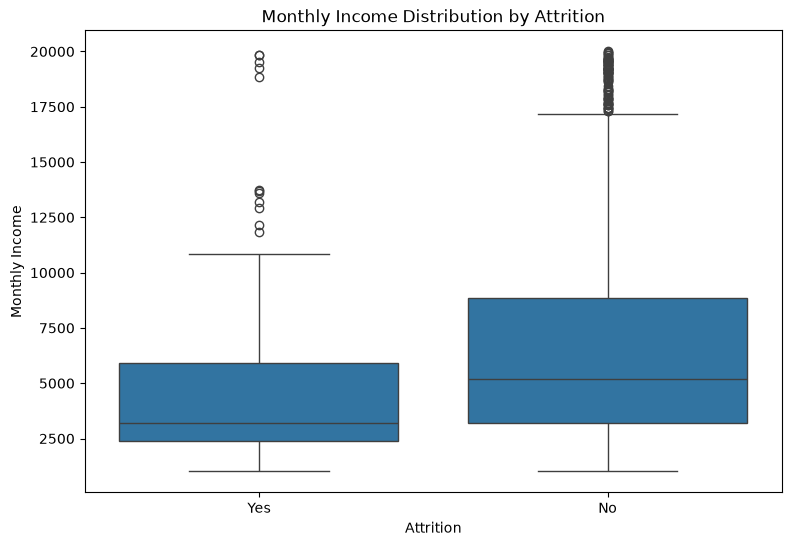

In [35]:
plt.figure(figsize=(9, 6))

sns.boxplot(data=df, x="Attrition", y="MonthlyIncome")

plt.title("Monthly Income Distribution by Attrition")
plt.xlabel("Attrition")
plt.ylabel("Monthly Income")

plt.show()

In [36]:
print("Stayed - Skewness:", stats.skew(income_stayed))
print("Left - Skewness:", stats.skew(income_left))

Stayed - Skewness: 1.2846660875596987
Left - Skewness: 1.908966310070742


In [37]:
welch_result = stats.ttest_ind(income_stayed, income_left, equal_var=False)

print("T-statistic:", welch_result.statistic)
print("P-value:", welch_result.pvalue)
print("Degrees of freedom:", welch_result.df)

T-statistic: 7.482621586644742
P-value: 4.433588628286069e-13
Degrees of freedom: 412.74074755747006


In [38]:
income_difference = income_stayed.mean() - income_left.mean()

n1 = len(income_stayed)
n2 = len(income_left)

se_difference = np.sqrt(income_stayed.var(ddof=1) / n1 + income_left.var(ddof=1) / n2)

critical_value = stats.t.ppf(0.975, welch_result.df)

margin_error = critical_value * se_difference

lower_ci = income_difference - margin_error
upper_ci = income_difference + margin_error

print("Mean Difference:", income_difference)
print("95% CI:", (lower_ci, upper_ci))

Mean Difference: 2045.646832363177
95% CI: (np.float64(1508.2435159484294), np.float64(2583.0501487779247))


In [39]:
pooled_sd = np.sqrt(
    ((n1 - 1) * income_stayed.var(ddof=1) + (n2 - 1) * income_left.var(ddof=1))
    / (n1 + n2 - 2)
)

cohens_d = income_difference / pooled_sd

correction = 1 - (3 / (4 * (n1 + n2) - 9))

hedges_g = correction * cohens_d

print("Cohen's d:", cohens_d)
print("Hedges' g:", hedges_g)

Cohen's d: 0.44001780335915724
Hedges' g: 0.43979296033240245


In [40]:
mannwhitney_result = stats.mannwhitneyu(
    income_stayed, income_left, alternative="two-sided"
)

print("U statistic:", mannwhitney_result.statistic)
print("P-value:", mannwhitney_result.pvalue)

U statistic: 191600.5
P-value: 2.950830917288873e-14


## Statistical Comparison: Monthly Income vs Employee Attrition

### Hypotheses

- **Null Hypothesis (H₀):** The mean monthly income of employees who stayed and employees who left is equal.
- **Alternative Hypothesis (H₁):** The mean monthly income of employees who stayed and employees who left is different.

### Descriptive Statistics

| Metric | Stayed | Left |
|---|---:|---:|
| Sample Size | 1,233 | 237 |
| Mean | 6,832.74 | 4,787.09 |
| Median | 5,204 | 3,202 |
| Standard Deviation | 4,818.21 | 3,640.21 |

### Distribution Examination

Both income distributions show positive skewness:

- Stayed: 1.2847
- Left: 1.9090

The income distributions are not perfectly symmetrical. Given the relatively large independent samples, Welch's t-test is used to compare mean incomes without assuming equal variances.

### Welch's Independent Samples t-test

- T-statistic: 7.4826
- Degrees of freedom: 412.74
- P-value: 4.4336 × 10⁻¹³
- Significance level: 0.05

### Confidence Interval

The estimated mean income difference (Stayed − Left) is 2,045.65.

The 95% confidence interval is:

(1,508.24, 2,583.05)

Since the interval does not contain zero, it supports a statistically significant difference in mean monthly income.

### Effect Size

- Cohen's d: 0.4400
- Hedges' g: 0.4398

Hedges' g indicates a small-to-moderate standardized difference between the two groups.

### Supplementary Mann–Whitney U Test

- U statistic: 191,600.5
- P-value: 2.9508 × 10⁻¹⁴

The supplementary test also indicates a statistically significant difference between the income distributions.

### Conclusion

There is statistically significant evidence that employees who stayed have higher average monthly income than employees who left.

The estimated mean difference is approximately 2,045.65, with a 95% confidence interval ranging from 1,508.24 to 2,583.05.

The effect size indicates a small-to-moderate difference. The Mann–Whitney U test provides additional evidence that the income distributions differ.

However, these findings establish an association between income and attrition status, not that lower income causes employees to leave.

In [41]:
p_values = {
    "Overtime": 8.15842372153832e-21,
    "Job Role": 2.752481638050657e-15,
    "Business Travel": 5.608614476449931e-06,
    "Job Satisfaction": 0.0005563004510387556,
    "Work-Life Balance": 0.0009725698845348824,
}

In [42]:
alpha = 0.05
number_of_tests = len(p_values)

adjusted_alpha = alpha / number_of_tests

print("Original significance level:", alpha)
print("Number of tests:", number_of_tests)
print("Adjusted significance level:", adjusted_alpha)

Original significance level: 0.05
Number of tests: 5
Adjusted significance level: 0.01


In [43]:
bonferroni_results = pd.DataFrame(
    {"Analysis": list(p_values.keys()), "Original_P_Value": list(p_values.values())}
)

bonferroni_results["Adjusted_P_Value"] = np.minimum(
    bonferroni_results["Original_P_Value"] * number_of_tests, 1
)

bonferroni_results["Significant_After_Correction"] = (
    bonferroni_results["Adjusted_P_Value"] < alpha
)

display(bonferroni_results)

,Analysis,Original_P_Value,Adjusted_P_Value,Significant_After_Correction
0,Overtime,8.158424e-21,4.079212e-20,True
1,Job Role,2.752482e-15,1.376241e-14,True
2,Business Travel,5.608614e-06,2.804307e-05,True
3,Job Satisfaction,5.563005e-04,2.781502e-03,True
4,Work-Life Balance,9.725699e-04,4.862849e-03,True


## Multiple Hypothesis Testing: Bonferroni Correction

### Purpose

Multiple hypothesis testing increases the probability of obtaining false-positive results when several statistical tests are performed.

To control the family-wise error rate, the Bonferroni correction was applied to the five categorical Chi-square tests.

### Method

The adjusted significance level was calculated as:

\[
\alpha_{\text{adjusted}}=\frac{\alpha}{m}
\]

Where:

- Original significance level (\(\alpha\)) = 0.05
- Number of tests (m) = 5

Therefore:

\[
\alpha_{\text{adjusted}}=\frac{0.05}{5}=0.01
\]

### Results

All five categorical relationships remained statistically significant after the Bonferroni correction:

- Overtime vs Attrition
- Job Role vs Attrition
- Business Travel vs Attrition
- Job Satisfaction vs Attrition
- Work-Life Balance vs Attrition

### Conclusion

All five selected categorical associations remain statistically significant after applying the Bonferroni correction.

This provides additional confidence that these findings are not simply the result of conducting multiple categorical hypothesis tests.

However, statistical significance does not establish causation, and the correction was limited to these five Chi-square tests.

## Limitations of Statistical Analysis

The statistical findings should be interpreted considering the following limitations:

1. **Observational Data:** The dataset contains observational employee information. Statistical associations do not establish causal relationships.

2. **Dataset Limitations:** The IBM HR Analytics dataset is a sample dataset and may not fully represent real-world workforce behaviour across different organizations and industries.

3. **Class Imbalance:** Only 237 out of 1,470 employees left the organization, representing approximately 16.12% of the workforce. This imbalance should be considered when interpreting attrition patterns.

4. **Weak Associations:** Several categorical variables showed statistically significant relationships with attrition, but their Cramér's V values indicate relatively weak associations.

5. **Multiple Hypothesis Testing:** The Bonferroni correction was applied to the five selected categorical Chi-square tests. Other analyses were not included in this correction.

6. **Confounding Variables:** Factors such as age, experience, job role, income and overtime may be related to one another. The individual statistical tests do not control for these potential confounding factors.

7. **Distributional Characteristics:** Monthly income distributions were positively skewed. Welch's t-test was used to compare means without assuming equal variances, while the Mann–Whitney U test provided a supplementary comparison of distributions.

### Overall Limitation

The findings identify statistical relationships and patterns within the available dataset. They should be used to guide further HR investigation rather than treated as definitive explanations of employee turnover.

# Statistical Analysis — Final Summary

## Overview

Statistical analysis was conducted to investigate the relationships between employee attrition and selected workforce characteristics using the IBM HR Analytics Employee Attrition dataset.

The analysis included numerical correlation, Chi-square tests of independence, effect size measurements, independent samples testing and confidence intervals.

## Key Findings

### 1. Numerical Correlation

- Total Working Years showed the strongest negative correlation with attrition (-0.1711).
- Distance From Home showed the strongest positive correlation (0.0779).
- All examined Pearson correlation coefficients were weak.

### 2. Categorical Associations

Five Chi-square tests identified statistically significant associations:

- Overtime vs Attrition: Cramér's V = 0.2441.
- Job Role vs Attrition: Cramér's V = 0.2421.
- Business Travel vs Attrition: Cramér's V = 0.1283.
- Job Satisfaction vs Attrition: Cramér's V = 0.1091.
- Work-Life Balance vs Attrition: Cramér's V = 0.1054.

Overtime and job role showed the strongest associations among the five categorical analyses.

All five relationships remained statistically significant after Bonferroni correction.

### 3. Monthly Income Comparison

Employees who stayed had an average monthly income of 6,832.74, compared with 4,787.09 for employees who left.

Welch's independent samples t-test indicated a statistically significant difference between the groups.

- Mean difference: 2,045.65
- P-value: 4.4336 × 10⁻¹³
- 95% Confidence Interval: (1,508.24, 2,583.05)
- Hedges' g: 0.4398

The supplementary Mann–Whitney U test also indicated a statistically significant difference in income distributions.

## Overall Conclusion

The statistical analysis identified several employee characteristics associated with attrition, particularly overtime, job role, business travel, job satisfaction, work-life balance and monthly income.

Overtime and job role demonstrated comparatively stronger categorical associations, while the monthly income comparison revealed a small-to-moderate standardized difference between employees who stayed and those who left.

These findings provide statistical support for several patterns identified during exploratory data analysis.

However, statistical significance does not establish causation. Further investigation involving multiple variables and potential confounding factors would be required to understand the underlying drivers of employee attrition.